# 1 · HAYEKIT：扩散、沉淀与孔隙率反馈

**这一篇学什么**

- 一个反应运移时间步怎样拆成**输运**和**化学**两步（SNIA）
- GEMS 里**动力学**矿物怎么处理：上下限每步移动 $r\,\Delta t$
- 孔隙率变化怎样反过来影响扩散
- 为什么化学求解器“收敛”了，时间步仍然重要

这是最适合入门的算例：一维、没有水流，而且有**解析解**
（Hayek, Kosakowski & Churakov, *Water Resour. Res.* 2011, 2012）。

## 问题

2 mm 的柱子。溶解物 A、B 从两端扩散进来（边界值随时间变化，取自解析解），生成固相

$$\mathrm{A + B \;\rightleftharpoons\; AB(s)}, \qquad \log K = -6.41 .$$

沉淀占据孔隙，孔隙率 $\phi$ 下降，有效扩散系数 $D_e = D_0\,\phi$ 也随之下降。

$$\frac{\partial (\phi c_i)}{\partial t} = \nabla\cdot\big(D_0\,\phi\,\nabla c_i\big) - \nu_i\, r ,\qquad
r = A_s\, k\,(1-\Omega),\quad A_s = 10^4\,\phi,\quad k = 10^{-7.69897}\ \mathrm{mol\,m^{-2}\,s^{-1}}$$

| 量 | 值 | OGS 文件 |
|---|---|---|
| 长度、网格 | 2 mm，100 个线单元 | `ab1d.msh` |
| $D_0$ | $10^{-10}$ m²/s，$D_e = D_0\phi$（`$DIFFUSION 9`） | `ab1d.mcp` |
| 动力学 | 速率模型 1，表面积模型 4：$A_s = 10^4\phi$ | `ab1d.gem` |
| 时间步 | 100 s × 100（OGS） | `ab1d.tim` |
| 初始状态 | OGS 在 $t=0$ 的重启文件 | `ab1d_*_gem.asc` |
| A、B 的边界值 | 4 条时间曲线 | `ab1d.rfd`、`ab1d.bc` |

## 准备

notebook 只用模板里的模块；算例数据（OGS 输入、GEMS 文件、参考结果）都在
`GEMS_FEniCSx_OGS5_Template/cases/2_hayekit`。

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p / 'GEMS_FEniCSx_OGS5_Template' for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'GEMS_FEniCSx_OGS5_Template').exists())
sys.path.insert(0, str(ROOT))
from ogs_io import read_msh, read_constant_blocks, read_restart, read_primary_values, read_vtk
from fe_mesh import OGSMesh
from transport import Transport
from gems_ogs import OGSGEMS, Kinetic
from ogs_models import harmonic_mean
from reactive_transport import run
from compare import error_table

CASE = ROOT / 'cases' / '2_hayekit'
OGS = CASE / 'ogs_input'
plt.rcParams.update({'figure.dpi': 110, 'font.size': 9, 'axes.grid': True, 'grid.alpha': 0.3})

## 网格和边界值

`OGSMesh` 用 OGS 的节点和单元建 dolfinx 网格，并保存 OGS 节点编号和 FEniCSx 自由度之间的映射。
**模板里所有状态数组都按 OGS 节点编号。**

两端 A、B 的值随时间变化（`ab1d.rfd` 里 4 条曲线）；H、O 和惰性组分取 `ab1d.bc` 的常数。

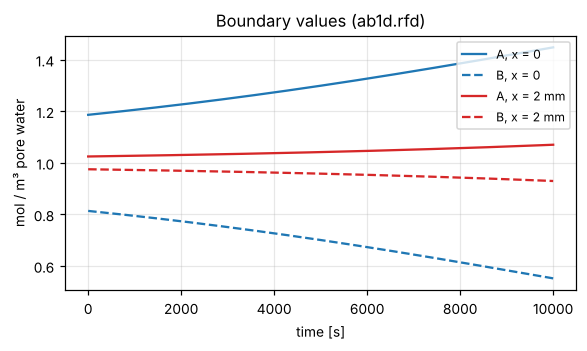

101 nodes, h = 2.0e-05 m


In [2]:
points, cells, _, _ = read_msh(OGS / 'ab1d.msh')
mesh = OGSMesh(points[:, :1], cells['line'], 'interval')
x = mesh.points[:, 0]
left, right = int(np.argmin(x)), int(np.argmax(x))

curves = []
for blk in (OGS / 'ab1d.rfd').read_text().split('#CURVES')[1:]:
    rows = [l.split()[:2] for l in blk.split('\n') if l.strip() and l.split()[0][0].isdigit()]
    curves.append(np.array(rows, float))
comps = ['1-Ael', '2-Bel', '3-H', '4-Inrt', '5-O', '6-Zz']
bc = {'POINT0': np.zeros(6), 'POINT1': np.zeros(6)}
for pcs, var, geo, val in read_constant_blocks(OGS / 'ab1d.bc', '#BOUNDARY_CONDITION'):
    if var in comps:
        bc[geo][comps.index(var)] = val

def boundary_values(t):
    v = np.vstack([bc['POINT0'], bc['POINT1']])
    v[0, :2] = [np.interp(t, *curves[0].T), np.interp(t, *curves[1].T)]
    v[1, :2] = [np.interp(t, *curves[2].T), np.interp(t, *curves[3].T)]
    return v

t = np.linspace(0, 1e4, 200)
fig, ax = plt.subplots(figsize=(6, 3))
for k, (lab, ls) in enumerate([('A, x = 0', '-'), ('B, x = 0', '--'), ('A, x = 2 mm', '-'), ('B, x = 2 mm', '--')]):
    ax.plot(t, np.interp(t, *curves[k].T), ls, color='C0' if k < 2 else 'C3', label=lab)
ax.set_xlabel('time [s]'); ax.set_ylabel('mol / m³ pore water'); ax.set_title('Boundary values (ab1d.rfd)')
ax.legend(fontsize=8); plt.show()
print(f'{mesh.n_nodes} nodes, h = {x[1] - x[0]:.1e} m')

## 化学：从 OGS 重启状态开始

这个基准从 OGS 重启文件开始：每个节点的孔隙率、流体体积、固相里的元素量（`b_fix`）、物种量和它们的
**动力学上下限** `dll`/`dul`。`init_from_restart` 读入这些，并在每个内部节点算一次 GEMS。

这里有两个 OGS 选项要注意：

- `hydrology='hayekit'`（`$FLAG_HAYEKIT 1`）：GEMS 之后只把溶剂水缩放到孔隙体积，溶质不缩放；
- `Kinetic('AB(s)', area_model=4, area=1e4)`：表面积 $A_s = 10^4\,\phi$。

两端节点是 Dirichlet 节点，不算化学（OGS 默认 `$CALCULATE_BOUNDARY_NODES 0`）。

elements: ['Ael', 'Bel', 'H', 'Inrt', 'O', 'Zz']
species : ['A@', 'B@', 'H2@', 'O2@', 'OH-', 'H+', 'H2O@', 'AB(s)', 'I(s)']


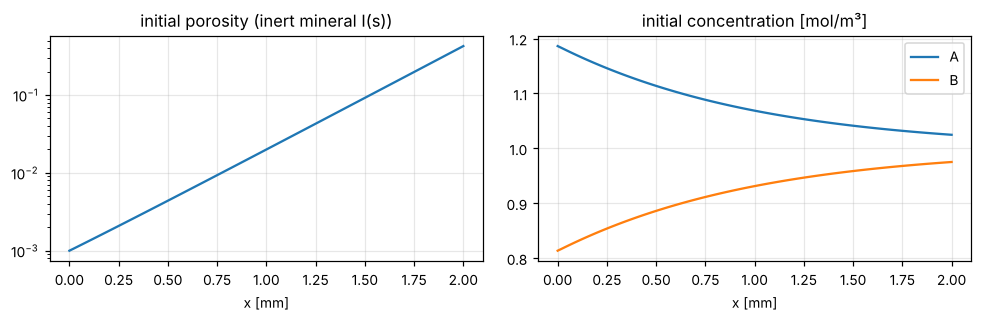

In [3]:
def make_chemistry():
    chem = OGSGEMS(CASE / 'gems' / 'TestSolub-dat.lst', mesh.n_nodes, hydrology='hayekit', min_porosity=1e-15,
                   kinetics=[Kinetic('AB(s)', logk=(-7.69897,), area_model=4, area=1.0e4)],
                   boundary_nodes=[left, right])
    restart = read_restart(OGS / 'ab1d', mesh.n_nodes, chem.nIC, chem.nDC)
    c0 = read_primary_values(OGS / 'ab1d', 'MASS_TRANSPORT', comps)
    chem.init_from_restart(restart, c0, nodes=np.flatnonzero(~chem.boundary), update_porosity=True)
    return chem

chem = make_chemistry()
print('elements:', chem.elements)
print('species :', chem.species)
o = np.argsort(x)
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].semilogy(x[o] * 1e3, chem.phi[o]); ax[0].set_title('initial porosity (inert mineral I(s))')
ax[1].plot(x[o] * 1e3, chem.c[o, 0], label='A'); ax[1].plot(x[o] * 1e3, chem.c[o, 1], label='B')
ax[1].set_title('initial concentration [mol/m³]'); ax[1].legend()
for a in ax: a.set_xlabel('x [mm]')
plt.tight_layout(); plt.show()

## 输运和时间循环

`Transport` 用线性单元和向后 Euler 解 $\phi\,\partial_t c - \nabla\cdot(D_e\nabla c) = 0$。
每一步之前 `prepare` 回调根据当前节点孔隙率更新单元系数，和 OGS 完全一样：

- 单元孔隙率 = 节点孔隙率的平均；
- 单元 $D_e$ = 节点值 $D_0\,\phi_i$ 的**调和**平均。

然后 `run` 对每个时间步：输运所有组分 → 每个内部节点算 GEMS
（浓度 → 质量、动力学上下限、平衡、孔隙率、速率、质量 → 浓度）。

In [4]:
D0 = 1.0e-10
t_end = 1.0e4

def simulate(dt):
    chem = make_chemistry()
    tr = Transport(mesh, fixed_nodes=[left, right])
    snaps = {}

    def prepare(step, t, dt):
        tr.phi_cell = chem.phi[mesh.cells].mean(1)
        tr.De_cell = harmonic_mean(D0 * chem.phi, mesh.cells)
        tr.fixed_values = boundary_values(t)

    def record(step, t, dt):
        if abs(t - 1000.0) < 1e-9 or abs(t - t_end) < 1e-9:
            snaps[t] = dict(A=chem.c[:, 0].copy(), B=chem.c[:, 1].copy(), phi=chem.phi.copy(),
                            AB=chem.amounts('AB(s)').copy())

    log = run(chem, tr, [dt] * int(round(t_end / dt)), prepare=prepare, record=record, print_every=0)
    print(f'dt = {dt:5g} s: {len(log)} steps in {log.wall_s.iloc[-1]:.1f} s, failed GEMS nodes: {log.failed.sum()}')
    return snaps

runs = {dt: simulate(dt) for dt in (100.0, 10.0, 1.0)}

dt =   100 s: 100 steps in 1.4 s, failed GEMS nodes: 0


dt =    10 s: 1000 steps in 14.2 s, failed GEMS nodes: 0


dt =     1 s: 10000 steps in 143.2 s, failed GEMS nodes: 0


## 和 OGS 比较（同样的时间步 100 s）

用 OGS 的时间步，结果和 OGS 输出一致到几个 $10^{-5}$（孔隙率 $3\times10^{-4}$）。

In [5]:
ogs = read_vtk(CASE / 'reference' / 'ab1d0100.vtk')
ro = np.argsort(ogs['points'][:, 0])
sel = o[1:-1]
r = runs[100.0][t_end]
table = error_table({'A': r['A'][sel], 'B': r['B'][sel], 'AB(s)': r['AB'][sel], 'porosity': r['phi'][sel]},
                    {'A': ogs['node__1-Ael'][ro][1:-1], 'B': ogs['node__2-Bel'][ro][1:-1],
                     'AB(s)': ogs['node__AB(s)'][ro][1:-1], 'porosity': ogs['node__NodePorosity'][ro][1:-1]})
display(table.style.hide(axis='index').format({'ref_max': '{:.3g}', 'max_abs_diff': '{:.2e}', 'max_rel_diff': '{:.2e}'}))

quantity,ref_max,max_abs_diff,max_rel_diff
A,1.45,2.84e-05,1.96e-05
B,0.927,2.84e-05,3.07e-05
AB(s),0.378,6.91e-06,1.83e-05
porosity,0.0217,6.90e-06,3.18e-04


## 和解析解比较——时间步很关键

在 $t = 10^4$ s，OGS 自己的孔隙率就和解析解**差 24 %**。原因是动力学是显式的：每步的沉淀速率用的是
*上一步*的 $\Omega$ 和 $\phi$。时间步缩小（100 s → 10 s → 1 s）按一阶收敛。

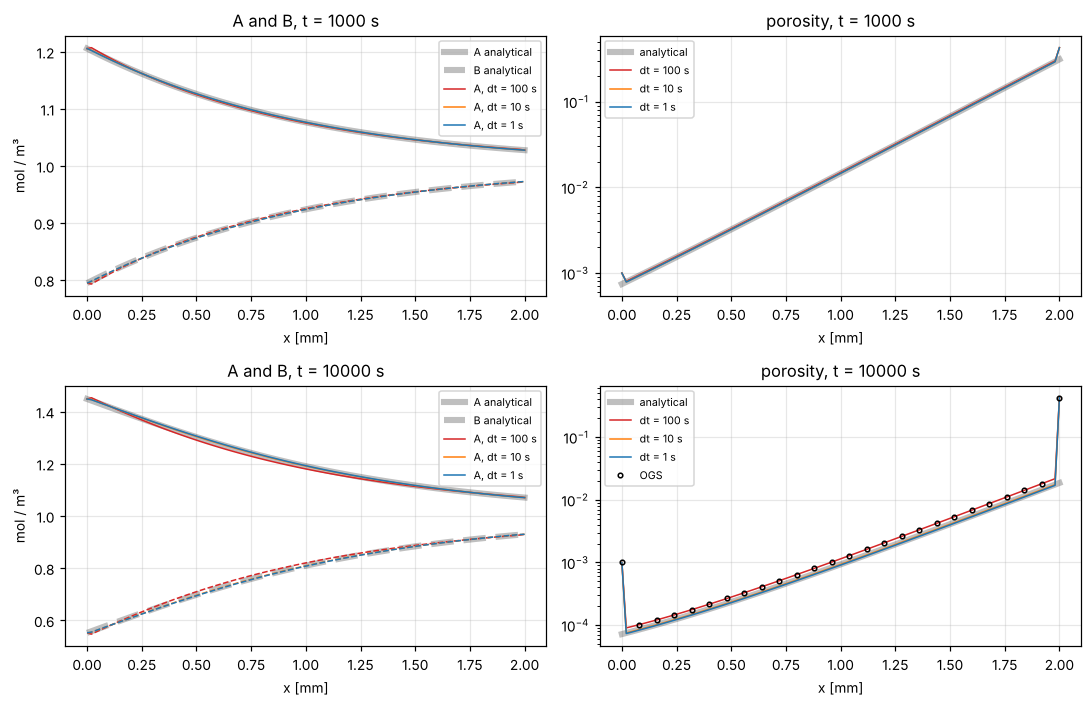

max. relative error of porosity,dt = 100 s,dt = 10 s,dt = 1 s
t = 1000 s,1.9%,0.1%,0.4%
t = 10000 s,24.2%,0.3%,2.7%


In [6]:
tab = np.load(CASE / 'reference' / 'hayekit_tables.npz')
xa = tab['analytical10ks__x'] * 1e3
colors = {100.0: 'C3', 10.0: 'C1', 1.0: 'C0'}
fig, axes = plt.subplots(2, 2, figsize=(10, 6.5))
for row, (tt, key) in enumerate([(1000.0, 'analytical1000s'), (t_end, 'analytical10ks')]):
    ax = axes[row, 0]
    ax.plot(xa, tab[key + '__C1x0'], 'k-', lw=4, alpha=0.25, label='A analytical')
    ax.plot(xa, tab[key + '__C2x0'], 'k--', lw=4, alpha=0.25, label='B analytical')
    for dt, s in runs.items():
        ax.plot(x[o] * 1e3, s[tt]['A'][o], '-', color=colors[dt], lw=1, label=f'A, dt = {dt:g} s')
        ax.plot(x[o] * 1e3, s[tt]['B'][o], '--', color=colors[dt], lw=1)
    ax.set_title(f'A and B, t = {tt:.0f} s'); ax.set_ylabel('mol / m³')
    ax = axes[row, 1]
    ax.semilogy(xa, tab[key + '__Porox0'], 'k-', lw=4, alpha=0.25, label='analytical')
    for dt, s in runs.items():
        ax.semilogy(x[o] * 1e3, s[tt]['phi'][o], color=colors[dt], lw=1, label=f'dt = {dt:g} s')
    if tt == t_end:
        ax.semilogy(ogs['points'][ro, 0][::4] * 1e3, ogs['node__NodePorosity'][ro][::4], 'ko', ms=3, mfc='none', label='OGS')
    ax.set_title(f'porosity, t = {tt:.0f} s')
for a in axes.flat:
    a.set_xlabel('x [mm]'); a.legend(fontsize=7)
plt.tight_layout(); plt.show()

rows = []
for tt, key in [(1000.0, 'analytical1000s'), (t_end, 'analytical10ks')]:
    for dt, s in runs.items():
        ana = tab[key + '__Porox0'][1:-1]
        rows.append({'time': f't = {tt:g} s', 'dt': f'dt = {dt:g} s', 'err': np.max(np.abs(s[tt]['phi'][sel] - ana) / ana)})
err = pd.DataFrame(rows).pivot(index='time', columns='dt', values='err')[[f'dt = {d:g} s' for d in runs]]
err.columns.name, err.index.name = 'max. relative error of porosity', None
display(err.style.format('{:.1%}'))

## 复现时遇到的坑

1. **关键字拼错。** `ab1d.gem` 写的是 `$FLAG_CALCULATE_BOUNDARY_NODE`，OGS 识别的是
   `$CALCULATE_BOUNDARY_NODES`。拼错的关键字被忽略，所以边界节点**不**算化学。OGS 输出可以证实：两端孔隙率始终不变。
2. **只缩放水**（`$FLAG_HAYEKIT`）。像其它算例那样缩放整个水相，结果明显不同。
3. **表面积模型 4**（$A_s = 10^4\phi$），不是模型 1（比表面积 × 矿物体积）。
4. **$D_e$ 调和平均、$\phi$ 算术平均、一致质量矩阵。** 换掉任何一个，和 OGS 的差就从 $10^{-5}$ 升到 $10^{-3}$ 以上。
5. **成核种子。** 不存在但过饱和的相给 1e-6 mol；没有它 AB(s) 永远不会从零开始长。
6. **每次冷启动。** GEMS 热启动时动力学相有时卡在旧的上下限不动。
7. **没解决的问题：** $\Delta t \to 0$ 时孔隙率和解析解仍差约 3 %（空间分辨率？边界节点不反应？解析解的假设？）。

## 练习

1. 用 `dt = 30` s 和 `dt = 3` s 再算，把 $t=10^4$ s 的孔隙率误差对 $\Delta t$ 画在对数坐标上。是一阶收敛吗？
2. 让边界节点也反应：建化学对象时用 `boundary_nodes=[]`（输运的 Dirichlet 节点保持不变）。两端孔隙率和 3 % 的极限误差怎么变？
3. 把 $D_e$ 的调和平均换成算术平均（`element_mean`）。柱子哪里变化最大？为什么是那里？